# Coding Project 2: Credit Analytics

**Names of all group members:**

Giulio Tonielli, Isabella Ceotto, Zhenbin Marco Fu, Ariba Mbeche

---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [2]:
# Exercise 1.
import numpy as np
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m, n = 20_000, 10_000
num_samples = m + n

# Columns: age, monthly income (in CHF 1000), self-employed indicator
x = np.column_stack([
    np.random.uniform(18, 80, size=num_samples),
    np.random.uniform(1, 15, size=num_samples),
    np.random.binomial(1, 0.10, size=num_samples),
])

# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)

# Training data: observations 1 through m
x_train = x[:m]

feature_names = [
    "Age (years)",
    "Monthly income (CHF 1000)",
    "Self-employed indicator",
]

for j, name in enumerate(feature_names):
    print(
        f"{name}: mean = {x_train[:, j].mean():.4f}, "
        f"standard deviation = {x_train[:, j].std(ddof=0):.4f}"
    )

# b) Can you come up with a few (2 or 3) additional features that may be relevant?
# (you don't have to implement those of course, just write down your answer in text)


Age (years): mean = 48.7427, standard deviation = 18.0074
Monthly income (CHF 1000): mean = 7.9865, standard deviation = 4.0308
Self-employed indicator: mean = 0.1017, standard deviation = 0.3023


### Exercise 1.b
Some additional features that could be relevant are:
- current/existing debt
- debt to income ratio
- history of employment (job stability)
- credit history (including past missed payments)
- what industry or occupation

In [3]:
# Exercise 2.
# Building the datasets:
sigmoid = lambda x: 1. / (1. + np.exp(-x))

# build the first dataset
def p1(x):
    return sigmoid(13.3 - 0.33 * x[:, 0] + 3.5 * x[:, 1] - 3 * x[:, 2])


# build the second dataset
def p2(x):
    age_out = ((x[:, 0] < 25) | (x[:, 0] > 75)).astype(float)
    return sigmoid(5 - 10 * age_out + 1.1 * x[:, 1] - x[:, 2])

xi = np.random.uniform(0, 1, size=num_samples)
y1 = (xi <= p1(x)).astype(int)
y2 = (xi <= p2(x)).astype(int)

x_test = x[m:] #We divide our dataset into training and test sets, 
#where the first m samples are used for training and the remaining n samples are used for testing.
datasets = {1: y1, 2: y2}
for s, y in datasets.items():
    print(f"Dataset {s}: share of good payers: train = {y[:m].mean():.4f}, test = {y[m:].mean():.4f}")

Dataset 1: share of good payers: train = 0.9515, test = 0.9523
Dataset 2: share of good payers: train = 0.9482, test = 0.9513


### Exercise 2

We defined the sigmoid function and the two repayment probabilities. In $p_1$ the log-odds are linear in the features. In $p_2$ the probability drops sharply for applicants younger than 25 or older than 75, which is a non-linear effect of age. We then drew $\xi_i \sim U(0,1)$ and set $y_i = 1$ if $\xi_i \le p(x_i)$, so that each borrower repays with probability $p(x_i)$. The same $\xi_i$ are used for both datasets, so the only difference between them is the true model. In both datasets about 95% of borrowers are good payers, so the classes are quite unbalanced.

In [4]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets

# Calculate and print the cross-entropy loss on both datasets for train and test
def cross_entropy(model, X, y) : 
    return log_loss(y, model.predict_proba(X))

logistic_models = {}
for s, y in datasets.items():
    logistic_models[s] = LogisticRegression(max_iter=1000).fit(x_train, y[:m])
    print(
        f"Dataset {s} Logistic regression: "
        f"cross-entropy loss on training data = {cross_entropy(logistic_models[s], x_train, y[:m]):.4f}, "
        f"cross-entropy loss on test data = {cross_entropy(logistic_models[s], x_test, y[m:]):.4f}"
    )


Dataset 1 Logistic regression: cross-entropy loss on training data = 0.0297, cross-entropy loss on test data = 0.0349
Dataset 2 Logistic regression: cross-entropy loss on training data = 0.1535, cross-entropy loss on test data = 0.1486


### Exercise 2.a

We wrote a small helper function that computes the cross-entropy loss from the predicted probabilities, and we fitted a logistic regression on the training data of each dataset. On dataset 1 the loss is low, since the true model $p_1$ has exactly the logistic form. On dataset 2 the loss is several times higher, because a model that is linear in age cannot capture the "too young or too old" effect in $p_2$. In both cases train and test losses are close, so the model does not overfit.

In [5]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)
sigma_hat = x_train.std(axis=0, ddof=0)
x_tilde = x / sigma_hat
xt_train, xt_test = x_tilde[:m], x_tilde[m:]


In [6]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.
svm_models = {}
for s, y in datasets.items():
    svm_models[s] = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True, random_state=42).fit(xt_train, y[:m])



c:\Users\fzbma\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\fzbma\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### Exercise 2.b (i)–(ii)

First, we compute the empirical standard deviation $\hat{\sigma}_j$ of each feature on the training data ($i = 1, \dots, m$). We then normalize both training and test data as $\tilde{x}_{ij} = x_{ij}/\hat{\sigma}_j$, as required by the exercise. We use only the training $\hat{\sigma}_j$, so no information from the test set is used. Note that this is a normalization, not a standardization: the mean is not subtracted.

- `SVC(kernel='rbf', gamma=0.1, C=0.2)` fits the SVM on the normalized training data, with kernel $k(x,x') = \exp(-\tfrac{1}{10}\|x-x'\|_2^2)$ and $C = 1/(2\lambda m) = 0.2$.
- `probability=True` adds Platt scaling: a logistic function is fitted on the SVM scores (via 5-fold cross-validation), so `predict_proba` returns repayment probabilities. `random_state=42` makes it reproducible.

**Note on the `FutureWarning`:** scikit-learn ≥ 1.9 marks `probability=True` as deprecated. It still works and performs Platt scaling as required. We kept it because the assignment suggests it; the equivalent new form is `CalibratedClassifierCV(SVC(...), method="sigmoid", ensemble=False)`. 

In [7]:
# Exercise 2.b (iii)
# "model.predict_proba(X)" predicts probabilities from features (note that it outputs both P(Y=0|X) and P(Y=1|X))

# Calculate and print the cross-entropy loss on both normalized datasets for train and test
for s, y in datasets.items():
    print(f"Dataset {s} - SVM (Platt): cross-entropy train = {cross_entropy(svm_models[s], xt_train, y[:m]):.4f}, "
          f"cross-entropy test = {cross_entropy(svm_models[s], xt_test, y[m:]):.4f}")

Dataset 1 - SVM (Platt): cross-entropy train = 0.0319, cross-entropy test = 0.0387
Dataset 2 - SVM (Platt): cross-entropy train = 0.0712, cross-entropy test = 0.0672


### Exercise 2.b (iii)

On dataset 1 both models perform similarly, since the log-odds of $p_1$ are linear in the features, which suits logistic regression. On dataset 2 the SVM is clearly better: the age effect in $p_2$ (below 25 or above 75) is non-linear, and the RBF kernel captures it while logistic regression cannot. Train and test losses are close, so there is no overfitting.

In [8]:
# Exercise 2.b (iv)
#Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning.



### Exercise 2.b (iv)

No, the results would not change if we use the standardized data instead of the normalized data.

The SVM only "sees" the data through the kernel $k(x,x') = \exp(-\tfrac{1}{10}\|x-x'\|^2)$, which depends only on the difference $x - x'$. Standardizing instead of normalizing means subtracting the constant $\hat{\mu}_j/\hat{\sigma}_j$ from every observation, and this cancels out in the difference:

$$\tilde{z}_i - \tilde{z}_{i'} = \tilde{x}_i - \tilde{x}_{i'}$$

So the distances between points are the same, the kernel matrix is the same, and the SVM gives exactly the same scores $\hat{f}^{svm}_s$. Since Platt scaling is fitted on these scores, the predicted probabilities and the cross-entropy losses would also be the same.

The division by $\hat{\sigma}_j$ is what actually matters, because it puts the features on comparable scales. Without it, age (std ≈ 18) would dominate the distance compared to the self-employed dummy (std ≈ 0.3). The mean subtraction is just a shift, and the RBF kernel is not affected by shifts.

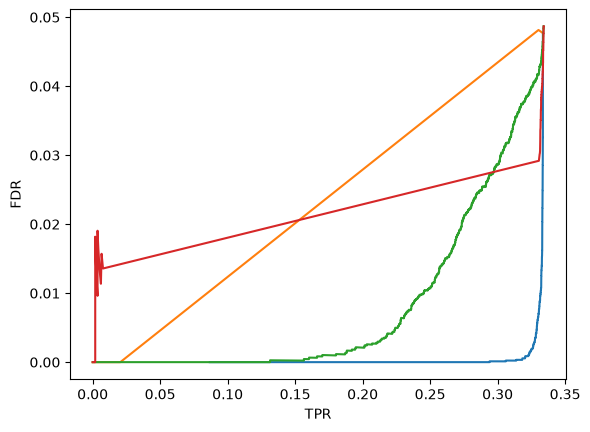

In [11]:
# Exercise 2.c
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.
import matplotlib.pyplot as plt
# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)


# first data set & logistic regression:
# (the code should be reusable for all cases, only exchanging datasets and predicted probabilities depending on the model)

def FDRTPRAUC(y_true,pred_proba):
      #reorder the elements from the smallest to the biggest
    thresholds = np.unique(pred_proba)[::-1]
    # Calculate positives (only depending on the dataset)
    P=np.sum(y==1)

    TPR_list = []
    FDR_list = []
    for th in thresholds:
        pred_positives = (pred_proba >= th)
        # Calculate true positives for all threshold values
        TP = np.sum(pred_positives & (y_true == 1))
        # Calculate false positives for all threshold values
        FP = np.sum(pred_positives & (y_true == 0))
        # Calculate FDR and TPR rate (points on the FDR/TPR curve) and the AUC
        FDR=FP/(FP+TP)
        TPR=TP/P
        TPR_list.append(TPR)
        FDR_list.append(FDR)
        
    TPR_array = np.array(TPR_list)
    FDR_array = np.array(FDR_list)
    
    #Computation for AUC    
    AUC=0
    for i in range(len(TPR_array) - 1):
        AUC+=(FDR_array[i]+FDR_array[i+1])/2*(TPR_array[i+1]-TPR_array[i])        
    return TPR_array, FDR_array, AUC
# second data set & logistic regression:
for s, y in datasets.items():
    y_test = y[m:]
    pred_proba = logistic_models[s].predict_proba(x_test)[:, 1]
    TPR_array, FDR_array, AUC=FDRTPRAUC(y_test, pred_proba)
    plt.plot(TPR_array,FDR_array, label=f'Dataset {s} LogReg (AUC = {AUC:.4f})')
    plt.xlabel('TPR')
    plt.ylabel('FDR')

# first data set and SVM:
# second data set and SVM:
    svm_pred_proba = svm_models[s].predict_proba(x_test)[:, 1]
    TPR_svm, FDR_svm, AUC_svm = FDRTPRAUC(y_test, svm_pred_proba)
    plt.plot(TPR_svm,FDR_svm, label=f'Dataset {s} LogReg (AUC = {AUC:.4f})')
    plt.xlabel('TPR')
    plt.ylabel('FDR')


# Print the AUC values.
# Briefly explain (in a Markdown cell or comments) how you construct the curves, interpret what
# the AUC means in this setting, and compare the two models on both data sets.

The curve is constructed by interpolation of the threshold given by the distinct predicted probability.

AUC in this setting means the average of the rate FDR/TPR rate.

In [10]:
# Exercise 3.

# Set model parameters and define matrix D
# (D has n x 50000 = 5*10^8 entries: a float64 array of uniforms of this size needs about 4 GB of memory.
#  If your machine runs out of memory, consider generating D in blocks of columns and/or storing it as booleans.)


# Strategy (i):
# Define Portfolio and possible outcomes for this portfolio using matrix D


# Plot histogram of profits and losses


# Calculate expected profit and losses and 95%-VaR


# Strategy (ii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the logistic regression model


# Plot histogram of profits and losses


# Calculate expected profit and losses and 95%-VaR


# Strategy (iii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the SVM model
# (evaluated on the normalized test features x~_i, see the assignment)


# Plot histogram of profits & losses (which is simply the performance of each strategy in scenario k, i.e. a profit if positive or a loss if negative)


# Calculate and print the expected profit & loss and 95%-VaR for each strategy (in CHF)


# c) Compare the three strategies and briefly interpret your results (Markdown cell or comments).

### Project Report

At the end of the notebook, provide a concise synthesis of your analysis. Do not simply repeat every answer above.

#### Approach
Briefly summarize how you generated the data, which models you fitted, and how you evaluated them and the lending strategies.

#### Model selection
Explain which classifier you would rely on for the lending decision and why. (The model hyperparameters are fixed by the assignment; no hyperparameter tuning is required.)

#### Key results
Summarize the most important quantitative results.

#### Interpretation
Explain what the results imply about the classification methods and the lending problem.

#### Robustness
Discuss how strongly your conclusions could depend on random elements of the analysis (e.g. simulation noise in the data and in the market scenarios). No additional experiments are required.

#### Limitations
State the main limitations of the analysis, the models, and the modelling assumptions.